In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/veronica-moran/eds220-hwk3.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

In [ ]:
# FINAL CODE

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

## 3. Import libraries

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [3]:
fp = os.path.join('data', 'Spill_Incidents_20261103.csv')
spills = gpd.read_file(fp)

fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)


<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

_Type your answer here, replacing this text._

In [61]:
#a. Check the dataframe's head

spills.head()

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered,geometry
spill_date,,,,,,,,,,,,,,,,,,,,
1900-01-01,2300485,BUS GARAGE,3867 NY-196,,HARTFORD,Washington,,5838,5,2023-04-18,Unknown,,Unknown,2025-01-15,unknown petroleum,Petroleum,0.0,,0.0,None
1900-01-01,9108142,REPUBLIC STEEL DUMP HUDSON RIVER (WATER ST?),HUDSON RIVER NEAR WWTP (MAIN ST? WATER ST?),REPUBLIC STEEL DUMP NEAR RCSD TREATMENT,TROY,Rensselaer,,4217,4,1991-10-04,Other,GROUNDWATER HUDSON $,Commercial/Industrial,1991-11-05,coal tar pitch volatiles,Hazardous Material,0.0,Pounds,0.0,None
1900-01-22,2208599,UNKNOWN PETROLEUM ONTO MTA TRACKS,640 CONDUIT BLVD,,BROOKLYN,Kings,,2401,2,2023-01-22,Unknown,,Unknown,2023-01-23,unknown petroleum,Petroleum,0.0,,0.0,None
1900-12-29,9010299,695 9TH AVE/MANH,695 9TH AVENUE,,MANHATTAN,New York,,3101,2,1990-12-22,Tank Overfill,,Commercial/Industrial,1994-11-16,#2 fuel oil,Petroleum,2.0,Gallons,0.0,None
1909-11-12,0909514,ROADSIDE DITCH,4510 EAST RAIL ROAD,,STOCKTON,Chautauqua,,0768,9,2009-11-25,Human Error,BEAR CREEK,Passenger Vehicle,2009-12-07,transmission fluid,Petroleum,2.0,Gallons,0.0,None


In [5]:
#b. Check the data types of the columns

spills.dtypes

Spill Number               object
Program Facility Name      object
Street 1                   object
Street 2                   object
Locality                   object
County                     object
ZIP Code                   object
SWIS Code                  object
DEC Region                 object
Spill Date                 object
Received Date              object
Contributing Factor        object
Waterbody                  object
Source                     object
Close Date                 object
Material Name              object
Material Family            object
Quantity                   object
Units                      object
Recovered                  object
geometry                 geometry
dtype: object

In [6]:
#c. Check the unique values in the `material_family` column

spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [7]:
#d. Check the unique values in the `county` column

spills['County'].unique().tolist()

['Westchester',
 'Queens',
 'Bronx',
 'Sullivan',
 'Cortland',
 'New York',
 'Ulster',
 'Kings',
 'Orange',
 'Dutchess',
 'Onondaga',
 'Saratoga',
 'Cayuga',
 'Oswego',
 'Warren',
 'Niagara',
 'Rockland',
 'Nassau',
 'Jefferson',
 'Schenectady',
 'Albany',
 'Monroe',
 'Schuyler',
 'St Lawrence',
 'Richmond',
 'Clinton',
 'Lewis',
 'Essex',
 'Chenango',
 'Erie',
 'Livingston',
 'Oneida',
 'Wayne',
 'Suffolk',
 'Orleans',
 'Ontario',
 'Genesee',
 'Otsego',
 'Tompkins',
 'Madison',
 'Chemung',
 'Seneca',
 'Broome',
 'Hamilton',
 'Washington',
 'Steuben',
 'Rensselaer',
 'Franklin',
 'Columbia',
 'Fulton',
 'Herkimer',
 'Schoharie',
 'Montgomery',
 'Putnam',
 'Delaware',
 'New Jersey - Region 2',
 'Tioga',
 'Chautauqua',
 'Cattaraugus',
 'Wyoming',
 'Yates',
 'Greene',
 'Pennsylvania - Region 9',
 'Allegany',
 'New Jersey - Region 3 (N)',
 'Cattaraugus Indian Reservation',
 'Connecticut - Region 3 (T)',
 'New Jersey - Region 3 (T)',
 'Canada - Region 6',
 'Canada - Region 9',
 'Pennsylvani

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [8]:
spills.columns = spills.columns.str.lower().str.replace(' ', '_')

spills.columns

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered', 'geometry'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [9]:
spills['quantity'].unique()
spills['recovered'].unique()

array(['0', '6', '2', '5', '3', '1', '40', '4', '25', '10', '19', '150',
       '15', '30', '100', '35', '350', '50', '200', '75', '2,800',
       '1,000', '90', '1.5', '20', '8', '55', '9', '39', '7', '175',
       '300', '265', '270', '275', '900', '1,200', '60', '225', '125',
       '500', '220', '253', '240', '0.5', '250', '80', '18', '140', '11',
       '45', '22,900', '450', '1,100', '110', '0.25', '36', '120', '70',
       '0.05', '130', '12', '230', '4,536', '287', '31', '700', '3,000',
       '172', '48', '13', '400', '38', '95', '135', '375', '192', '85',
       '188', '123', '2,500', '42', '215', '490', '180', '7.5', '231',
       '65', '62', '741', '2,000', '492', '53', '850', '1,500', '600',
       '0.9', '0.13', '43', '1,300', '277', '1,700', '24', '190', '3,500',
       '475', '0.1', '105', '956', '115', '149', '185', '4,620', '249',
       '165', '340', '320', '129', '202', '560', '5,000', '4,700',
       '2,400', '550', '280', '112', '395', '170', '9,400', '102', '307'

In [10]:
spills['spill_date'] = pd.to_datetime(spills['spill_date'])
spills['received_date'] = pd.to_datetime(spills['received_date'])
spills['close_date'] = pd.to_datetime(spills['close_date'])
spills['quantity'] = spills['quantity'].str.replace(',', '').astype('float64')
spills['recovered'] = spills['recovered'].str.replace(',', '').astype('float64')

In [13]:
spills.head(20)

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,...,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered,geometry
0,0107132,MH 864,RT 119/MILLWOOD RD,,ELMSFORD,Westchester,,6000,3,2001-10-10,...,Unknown,,Unknown,2001-10-15,unknown material,Other,10.0,Gallons,0.0,None
1,0405586,BOWRY BAY,WATER POLL CONTROL,,QUEENS,Queens,,4101,2,2004-08-21,...,Other,EAST RIVER,Unknown,2004-09-17,raw sewage,Other,0.0,,0.0,None
2,0405586,BOWRY BAY,WATER POLL CONTROL,,QUEENS,Queens,,4101,2,2004-08-21,...,Other,EAST RIVER,Unknown,2004-09-17,raw sewage,Other,0.0,Pounds,0.0,None
3,0204667,POLE 16091,GRACE AVE/BURKE AVE,,BRONX,Bronx,,0301,2,2002-08-02,...,Equipment Failure,,Commercial/Industrial,2002-10-28,transformer oil,Petroleum,1.0,Gallons,0.0,None
4,0210559,POLE ON,FERDALE LOMIS RD / RT 52,,LIBERTY,Sullivan,,5336,3,2003-01-20,...,Traffic Accident,,Commercial/Industrial,2003-01-22,transformer oil,Petroleum,6.0,Gallons,6.0,None
5,0311484,PRIVATE RESIDENCE,6568 GLEN HAVEN RD,,SCOTT,Cortland,,1238,7,2004-01-11,...,Equipment Failure,,Private Dwelling,2004-08-25,#2 fuel oil,Petroleum,75.0,Gallons,0.0,None
6,0104307,149TH RD,"183RD ST, 149TH AV& 149RD",,QUEENS,Queens,,4101,2,2001-07-23,...,Abandoned Drums,,Unknown,2001-08-01,unknown material,Other,0.0,Gallons,0.0,None
7,0160046,ABANDONED DRUMS,BAKER SCHOOL HOUSE ROAD,,SOLON,Cortland,,1200,7,2001-11-23,...,Abandoned Drums,,Unknown,2002-05-14,unknown material,Other,0.0,Gallons,0.0,None
8,9606869,AMSTERDAM AVE,WEST 79 TH STREET,,NYC,New York,,3101,2,1996-08-28,...,Traffic Accident,,Commercial Vehicle,1996-08-29,antifreeze,Other,2.0,Gallons,2.0,None
9,0312198,APARTMENT BUILDING,4 SOUTH SIDE TERRACE APAR,,NEW PALTZ,Ulster,,5638,3,2004-02-02,...,Tank Failure,,Commercial/Industrial,2004-04-05,#2 fuel oil,Petroleum,0.0,Pounds,0.0,None


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [26]:
spills = spills.set_index('spill_date').sort_index()

In [31]:
petr_23 = spills[spills['material_family']== 'Petroleum'].loc['2023']

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [40]:
print(f"Year in data: {petr_23.index.year.unique()}")
print(f"Months in data: {petr_23.index.month.unique()}")

Year in data: Index([2023], dtype='int32', name='spill_date')
Months in data: Index([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], dtype='int32', name='spill_date')


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [65]:
for material in petr_23['material_family']:
    assert material == 'Petroleum'

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

_Type your answer here, replacing this text._

In [73]:
print(f"Number of rows: {petr_23.shape[0]}")
print(f"Number of unique spills: {petr_23['spill_number'].nunique()}")

Number of rows: 8468
Number of unique spills: 8228


In [70]:
petr_23.shape

(8468, 20)

<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [76]:
petr_23['spill_number'].nunique()

8228

In [81]:
petr_23['spill_number']

spill_date
2023-01-01    2208970
2023-01-01    2208105
2023-01-01    2208120
2023-01-01    2208106
2023-01-01    2208111
               ...   
2023-12-31    2307945
2023-12-31    2307937
2023-12-31    2307944
2023-12-31    2307943
2023-12-31    2307946
Name: spill_number, Length: 8468, dtype: object

In [131]:
spills_per_county = petr_23.groupby('county')['spill_number'].nunique().rename('n_spills').reset_index()
spills_per_county = pd.DataFrame(spills_per_county)


In [132]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

_Type your answer here, replacing this text._

In [133]:
# a

counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [134]:
# b

counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [135]:
# c

counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

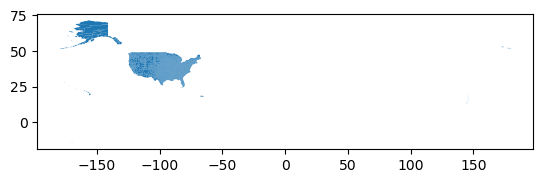

In [139]:
# d
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add counties point plot to our figure's axes
counties.plot(ax=ax)

# Display figure
plt.show()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [146]:
counties.columns = counties.columns.str.lower()

In [147]:
counties.columns

Index(['statefp', 'countyfp', 'countyns', 'geoid', 'geoidfq', 'name',
       'namelsad', 'lsad', 'classfp', 'mtfcc', 'csafp', 'cbsafp', 'metdivfp',
       'funcstat', 'aland', 'awater', 'intptlat', 'intptlon', 'geometry'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [151]:
ny_counties = counties[counties['statefp']=='36']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [ ]:
diff_names_spills = ...
diff_names_spills


In [ ]:
grader.check("7Ac")

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [ ]:
diff_names_ny = ...
diff_names_ny

In [ ]:
grader.check("7Ad")

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [ ]:
# e. 

### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [ ]:
# a 


b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

_Type your answer here, replacing this text._

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.